# Assignment 53 — Week 6, Day 4
## Topic: Machine Learning — Decision Tree Classification

**Objective:** Complete the exercise on decision-tree classification.

**Reference:** https://www.datacamp.com/community/tutorials/decision-tree-classification-python

A decision tree is a flowchart-like model. Each internal node tests one feature, each branch is an outcome of the test, and each leaf node gives a class. The tree is built by repeatedly choosing the split that best separates the classes, measured with an **attribute selection measure** such as **information gain (entropy)** or the **Gini index**.

This notebook follows the DataCamp tutorial and predicts diabetes on the Pima Indians Diabetes data set (`diabetes.csv`, which must be in the same folder).

**Diagram:** A simplified tree showing how splits lead to a prediction (the split values are illustrative).

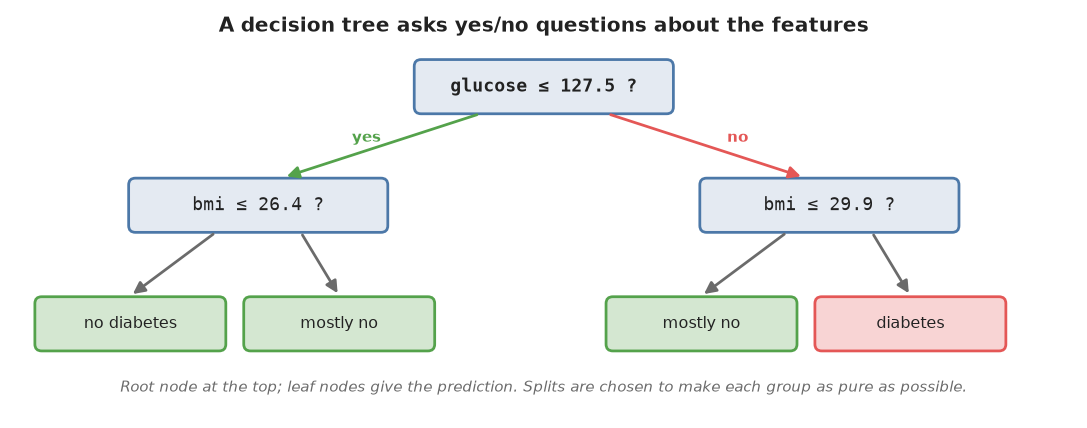

**Load the Pima Indians Diabetes dataset**

In [1]:
import pandas as pd

pima = pd.read_csv("diabetes.csv")

print(pima.head())
print(pima.shape)
print(pima["label"].value_counts())

   pregnant  glucose  bp  skin  insulin   bmi  pedigree  age  label
0         6      148  72    35        0  33.6     0.627   50      1
1         1       85  66    29        0  26.6     0.351   31      0
2         8      183  64     0        0  23.3     0.672   32      1
3         1       89  66    23       94  28.1     0.167   21      0
4         0      137  40    35      168  43.1     2.288   33      1
(768, 9)
label
0    500
1    268
Name: count, dtype: int64


**Explanation:** The dataset has 768 patients with 8 medical measurements each. label is 1 if the patient has diabetes and 0 if not.

**Select the features and split the data**

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

pima = pd.read_csv("diabetes.csv")

feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima.label

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

print("Training rows:", X_train.shape[0])
print("Test rows:", X_test.shape[0])

Training rows: 537
Test rows: 231


**Explanation:** X holds the feature columns and y holds the target (label). 70% of the rows are used for training and 30% for testing.

**Build and evaluate the decision tree**

In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

clf = DecisionTreeClassifier(random_state=1)
clf = clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("Tree depth:", clf.get_depth())
print("Number of leaves:", clf.get_n_leaves())

Accuracy: 0.6623376623376623
Tree depth: 15
Number of leaves: 104


**Explanation:** DecisionTreeClassifier splits the data again and again on the feature that best separates the classes. With no limits, the tree grows very deep and learns the training data too closely (overfitting), which lowers test accuracy.

**Diagram:** Training and test accuracy for trees of different depths on this data.

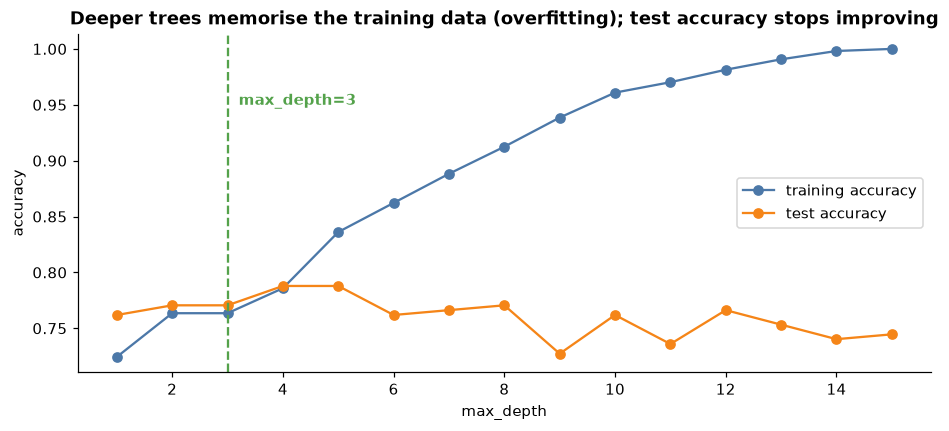

**Optimise the decision tree**

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf = clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print(metrics.confusion_matrix(y_test, y_pred))

Accuracy: 0.7705627705627706
[[124  22]
 [ 31  54]]


**Explanation:** criterion='entropy' uses information gain to choose splits, and max_depth=3 limits the tree to 3 levels. This pruning stops overfitting, and the accuracy improves.

**Visualise the decision tree**

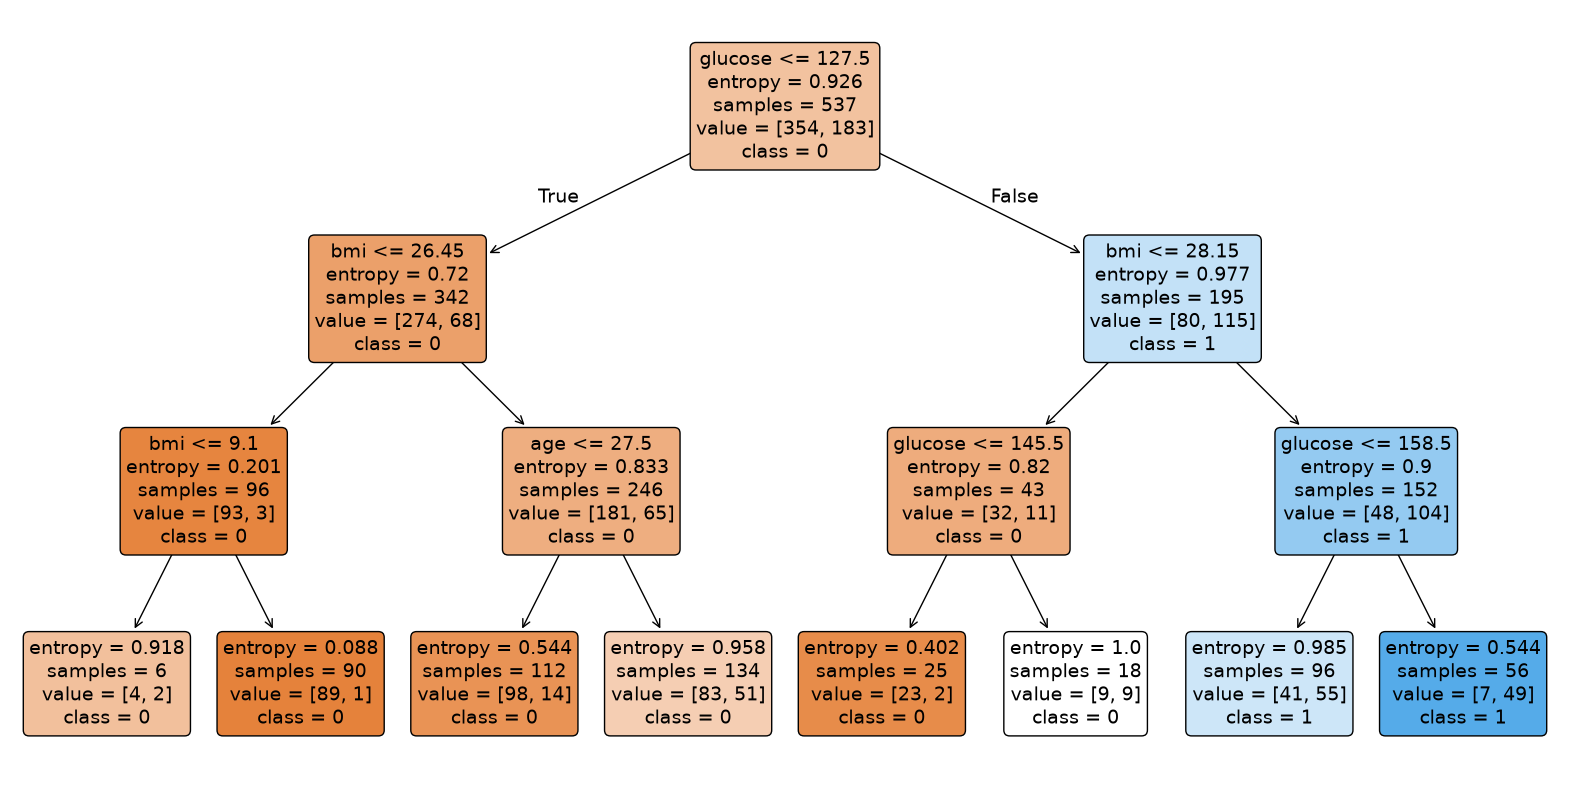

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

pima = pd.read_csv("diabetes.csv")
feature_cols = ["pregnant", "insulin", "bmi", "age", "glucose", "bp", "pedigree"]
X = pima[feature_cols]
y = pima.label
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

clf = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
clf = clf.fit(X_train, y_train)

plt.figure(figsize=(20, 10))
plot_tree(clf, feature_names=feature_cols, class_names=["0", "1"], filled=True, rounded=True)
plt.show()

**Explanation:** plot_tree() draws the tree. Each box shows the split rule, the entropy, the number of samples and the predicted class. The article uses Graphviz for this; plot_tree gives the same picture without extra installs.

## Observation

- A decision tree classifies data with a sequence of yes/no questions about the features.
- Splits are chosen with an attribute selection measure such as entropy (information gain) or Gini.
- The unpruned tree grew very deep and reached only about 66% test accuracy because it overfitted the training data.
- Limiting the tree to max_depth=3 with entropy raised test accuracy to about 77%.
- The tree can be drawn and read like a flowchart, which makes its decisions easy to explain.

## Conclusion

Decision trees are easy to understand and need little data preparation, but they overfit easily. Pruning, for example with max_depth, gives a simpler tree that generalises better to new data.